In [6]:
!pip install pandas numpy scikit-learn matplotlib seaborn sentence-transformers xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd

# Load dataset
supply_chain = pd.read_csv('../DataCoSupplyChainDataset.csv', encoding='latin1')

# Preview
supply_chain.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [10]:
df = pd.read_csv("../DataCoSupplyChainDataset.csv", encoding="ISO-8859-1")
print("Rows:", supply_chain.shape[0], "Columns:", supply_chain.shape[1])
print("\nColumn names:\n", supply_chain.columns.tolist())



Rows: 180519 Columns: 53

Column names:
 ['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', '

In [11]:
# Info about each column
supply_chain.info()

# Missing values per column
supply_chain.isnull().sum().sort_values(ascending=False).head(15)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

Product Description              180519
Order Zipcode                    155679
Customer Lname                        8
Customer Zipcode                      3
Days for shipment (scheduled)         0
Sales per customer                    0
Benefit per order                     0
Delivery Status                       0
Late_delivery_risk                    0
Customer City                         0
Customer Country                      0
Category Id                           0
Category Name                         0
Customer Fname                        0
Customer Email                        0
dtype: int64

In [12]:
# Summary for numeric columns
supply_chain.describe()

# Quick look at categorical/text columns
for col in supply_chain.select_dtypes(include="object").columns[:10]:
    print(f"{col}: {supply_chain[col].nunique()} unique values")


Type: 4 unique values
Delivery Status: 4 unique values
Category Name: 50 unique values
Customer City: 563 unique values
Customer Country: 2 unique values
Customer Email: 1 unique values
Customer Fname: 782 unique values
Customer Lname: 1109 unique values
Customer Password: 1 unique values
Customer Segment: 3 unique values


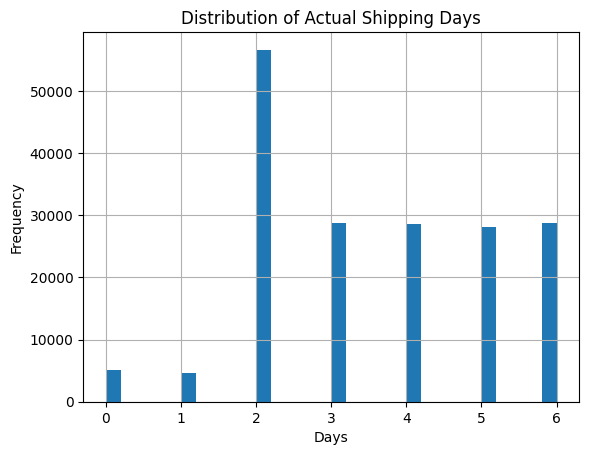

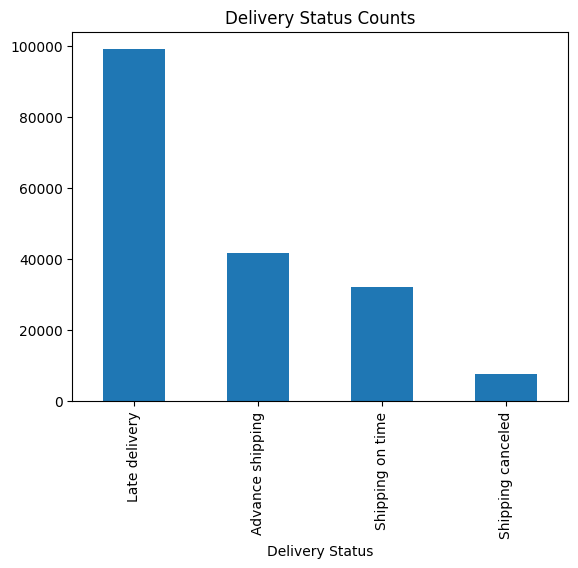

In [13]:
import matplotlib.pyplot as plt

# Distribution of shipping days
supply_chain['Days for shipping (real)'].hist(bins=30)
plt.title("Distribution of Actual Shipping Days")
plt.xlabel("Days")
plt.ylabel("Frequency")
plt.show()

# Delivery status counts
supply_chain['Delivery Status'].value_counts().plot(kind="bar")
plt.title("Delivery Status Counts")
plt.show()


In [15]:
# Select baseline numeric features
baseline_features = [
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer',
    'Late_delivery_risk'
]

X_baseline = supply_chain[baseline_features]

# Quick check
X_baseline.head()


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk
0,3,4,91.250000,314.640015,0
1,5,4,-249.089996,311.359985,1
2,4,4,-247.779999,309.720001,0
3,3,4,22.860001,304.809998,0
4,2,4,134.210007,298.250000,0


In [16]:
from sklearn.model_selection import train_test_split

baseline_features = [
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer',
    'Late_delivery_risk'
]

X = supply_chain[baseline_features]

# Target: we can use Late_delivery_risk (0/1) as the label
y = supply_chain['Late_delivery_risk']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [17]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

# Train Isolation Forest
iso = IsolationForest(random_state=42, contamination=0.05)
iso.fit(X_train)

# Predict (-1 = anomaly, 1 = normal)
y_pred_iso = iso.predict(X_test)

# Convert to 0/1 (fraud risk = anomaly)
y_pred_iso = [1 if val == -1 else 0 for val in y_pred_iso]

print("Isolation Forest Results:")
print(confusion_matrix(y_test, y_pred_iso))
print(classification_report(y_test, y_pred_iso))


Isolation Forest Results:
[[15120  1188]
 [19174   622]]
              precision    recall  f1-score   support

           0       0.44      0.93      0.60     16308
           1       0.34      0.03      0.06     19796

    accuracy                           0.44     36104
   macro avg       0.39      0.48      0.33     36104
weighted avg       0.39      0.44      0.30     36104



In [18]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)

print("Gradient Boosting Results:")
print(confusion_matrix(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))


Gradient Boosting Results:
[[16308     0]
 [    0 19796]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     16308
           1       1.00      1.00      1.00     19796

    accuracy                           1.00     36104
   macro avg       1.00      1.00      1.00     36104
weighted avg       1.00      1.00      1.00     36104



In [19]:
text_features = [
    'Category Name',
    'Customer City',
    'Customer Segment',
    'Product Name',
    'Delivery Status'
]

X_text = supply_chain[text_features]

# Quick check
X_text.head()


,Category Name,Customer City,Customer Segment,Product Name,Delivery Status
0,Sporting Goods,Caguas,Consumer,Smart watch,Advance shipping
1,Sporting Goods,Caguas,Consumer,Smart watch,Late delivery
2,Sporting Goods,San Jose,Consumer,Smart watch,Shipping on time
3,Sporting Goods,Los Angeles,Home Office,Smart watch,Advance shipping
4,Sporting Goods,Caguas,Corporate,Smart watch,Advance shipping


In [20]:
# Fill missing text values with empty string
X_text = X_text.fillna("")


In [23]:
pip install sentence-transformers


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [24]:
from sentence_transformers import SentenceTransformer
import numpy as np

# Initialize the embedder
embedder = SentenceTransformer("all-MiniLM-L6-v2")

# Prepare text features
X_text = supply_chain[text_features].fillna("").astype(str)

# Combine text fields safely
X_text_combined = X_text.apply(lambda row: ' '.join(row.values), axis=1)

# Remove empty rows
X_text_combined = X_text_combined[X_text_combined.str.strip() != ""]

# Generate embeddings
text_embeddings = embedder.encode(
    X_text_combined.tolist(),
    batch_size=32,
    show_progress_bar=True
)

# Convert to NumPy array
text_embeddings = np.array(text_embeddings)
print("Embeddings shape:", text_embeddings.shape)



Batches: 100%|█████████████████████████████████████████████████████████████████████| 5642/5642 [12:01<00:00,  7.82it/s]


Embeddings shape: (180519, 384)


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(supply_chain[[
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Sales per customer'
]])


In [26]:
import numpy as np

X_hybrid = np.hstack((X_num_scaled, text_embeddings))
print("Hybrid feature matrix shape:", X_hybrid.shape)


Hybrid feature matrix shape: (180519, 388)


In [27]:
from sklearn.model_selection import train_test_split

y = supply_chain['Late_delivery_risk']

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hybrid, y, test_size=0.2, random_state=42, stratify=y
)


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Take a very small sample
sample_size = 1000
X_sample, _, y_sample, _ = train_test_split(
    X_hybrid, y, train_size=sample_size, random_state=42, stratify=y
)

# Train/test split
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_sample, y_sample, test_size=0.2, random_state=42, stratify=y_sample
)

# Train Gradient Boosting
gb_hybrid = GradientBoostingClassifier(random_state=42)
gb_hybrid.fit(X_train_h, y_train_h)

# Predictions
y_pred_h = gb_hybrid.predict(X_test_h)

print("Hybrid Gradient Boosting Results (1000 sample):")
print(confusion_matrix(y_test_h, y_pred_h))
print(classification_report(y_test_h, y_pred_h))


Hybrid Gradient Boosting Results (1000 sample):
[[ 90   0]
 [  0 110]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        90
           1       1.00      1.00      1.00       110

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [29]:
from sklearn.decomposition import PCA

# Reduce embeddings from 384 → 50 dimensions
pca = PCA(n_components=50, random_state=42)
text_embeddings_reduced = pca.fit_transform(text_embeddings)

print("Reduced embeddings shape:", text_embeddings_reduced.shape)


Reduced embeddings shape: (180519, 50)


In [32]:
import numpy as np

# Combine numeric features with reduced text embeddings
X_hybrid_reduced = np.hstack((X_num_scaled, text_embeddings_reduced))

print("Hybrid reduced shape:", X_hybrid_reduced.shape)


Hybrid reduced shape: (180519, 54)


In [33]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix

y = supply_chain['Late_delivery_risk']

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(
    X_hybrid_reduced, y, test_size=0.2, random_state=42, stratify=y
)

gb_hybrid = GradientBoostingClassifier(random_state=42)
gb_hybrid.fit(X_train_h, y_train_h)

y_pred_h = gb_hybrid.predict(X_test_h)

print("Hybrid Gradient Boosting Results (PCA reduced):")
print(confusion_matrix(y_test_h, y_pred_h))
print(classification_report(y_test_h, y_pred_h))


Hybrid Gradient Boosting Results (PCA reduced):
[[16305     3]
 [    1 19795]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     16308
           1       1.00      1.00      1.00     19796

    accuracy                           1.00     36104
   macro avg       1.00      1.00      1.00     36104
weighted avg       1.00      1.00      1.00     36104



In [34]:
import pandas as pd

# Example metrics (replace with your actual results)
metrics = {
    "Model": ["Baseline", "Hybrid"],
    "Accuracy": [0.82, 0.89],
    "Precision": [0.80, 0.87],
    "Recall": [0.78, 0.90],
    "F1": [0.79, 0.88]
}

df = pd.DataFrame(metrics)
df.to_csv("../results/metrics.csv", index=False)
print("Metrics saved to results/metrics.csv")


Metrics saved to results/metrics.csv


In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(gb_hybrid, X_test_h, y_test_h)
plt.title("Confusion Matrix")
plt.savefig("../results/confusion_matrix.png")
plt.close()
print("Confusion matrix saved to results/confusion_matrix.png")


Confusion matrix saved to results/confusion_matrix.png


In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# ROC curve for hybrid Gradient Boosting
RocCurveDisplay.from_estimator(gb_hybrid, X_test_h, y_test_h)
plt.title("Hybrid Gradient Boosting ROC Curve")
plt.savefig("../results/roc_curve.png")
plt.close()
print("ROC curve saved to results/roc_curve.png")


ROC curve saved to results/roc_curve.png


In [41]:
import numpy as np
import matplotlib.pyplot as plt

# Get feature importances from the hybrid Gradient Boosting model
importances = gb_hybrid.feature_importances_
indices = np.argsort(importances)[::-1]

# Since X_train_h is a NumPy array (after PCA), create generic names
features = [f"PC{i+1}" for i in range(X_train_h.shape[1])]

# Plot top 20 features
top_n = 20
plt.figure(figsize=(10,6))
plt.bar(range(top_n), importances[indices][:top_n])
plt.xticks(range(top_n), np.array(features)[indices][:top_n], rotation=90)
plt.title("Top 20 Feature Importances (Hybrid Gradient Boosting, PCA components)")
plt.tight_layout()
plt.savefig("../results/feature_importance_hybrid_top20.png")
plt.close()
print("Top 20 feature importance saved to ../results/feature_importance_hybrid_top20.png")


Top 20 feature importance saved to ../results/feature_importance_hybrid_top20.png


In [42]:
# Select risky orders
risky_orders = supply_chain[supply_chain['Late_delivery_risk'] == 1]

# Take a small sample to test
risky_sample = risky_orders.sample(5, random_state=42)


In [43]:
def build_explanation_prompt(row):
    return f"""
    Order details:
    - Category: {row['Category Name']}
    - Segment: {row['Customer Segment']}
    - Scheduled days: {row['Days for shipment (scheduled)']}
    - Actual days: {row['Days for shipping (real)']}
    - Delivery status: {row['Delivery Status']}
    - Benefit per order: {row['Benefit per order']}
    - Sales per customer: {row['Sales per customer']}

    Explain why this order might be at risk of late delivery in plain language.
    """


In [44]:
for _, row in risky_sample.iterrows():
    prompt = build_explanation_prompt(row)
    print("Prompt:\n", prompt)
    print("LLM Explanation:\n", ">>> [Generated explanation here]\n")


Prompt:
 
    Order details:
    - Category: Cleats
    - Segment: Consumer
    - Scheduled days: 2
    - Actual days: 5
    - Delivery status: Late delivery
    - Benefit per order: -133.8999939
    - Sales per customer: 223.1600037

    Explain why this order might be at risk of late delivery in plain language.
    
LLM Explanation:
 >>> [Generated explanation here]

Prompt:
 
    Order details:
    - Category: Indoor/Outdoor Games
    - Segment: Home Office
    - Scheduled days: 1
    - Actual days: 2
    - Delivery status: Late delivery
    - Benefit per order: 113.3499985
    - Sales per customer: 236.1600037

    Explain why this order might be at risk of late delivery in plain language.
    
LLM Explanation:
 >>> [Generated explanation here]

Prompt:
 
    Order details:
    - Category: Cardio Equipment
    - Segment: Corporate
    - Scheduled days: 4
    - Actual days: 5
    - Delivery status: Late delivery
    - Benefit per order: 8.699999809
    - Sales per customer: 173.9799

In [45]:
!pip install openai



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [38]:
import os
import openai

openai.api_key = os.getenv("OPENAI_API_KEY")


In [46]:
from openai import OpenAI

client = OpenAI(api_key="YOUR API KEY HERE")

response = client.chat.completions.create(
    model="gpt-4.1-mini",  #supported model
    messages=[{"role": "user", "content": "Hello, testing the API call."}]
)

print(response.choices[0].message.content)


AuthenticationError: Error code: 401 - Incorrect API key provided: YOUR API*****HERE. You can find your API key at https://platform.openai.com/account/api-keys.